# Kinematic slip on a triangular mesh, step 1: the synthetic data and a least squares solution

This is the first step of a kinematic slip inversion on a fault meshed with triangles. It prepares everything with [CSI](https://github.com/jolivetr/csi) (`TriangularPatchesKin`): the kinematic and static Green's functions of a curved, slab-like fault, a synthetic rupture and its data, and a linear least squares solution for its slip history. It follows CSI's tutorial `notebooks/tutoTriangularKinematic.ipynb`, except for the synthetic rupture: here its rupture velocity varies over the fault, and its slip history comes from AlTar's own kinematic model. It writes AlTar's inputs to `input/`, with the true model and the least squares solution, which [step 2](step2_altar.ipynb) compares with AlTar's posterior.

The fault is a curved, slab-like surface whose dip steepens with depth; the stations are on land, as for a subduction earthquake; the data are bandpassed displacement waveforms, static GPS offsets and an InSAR line of sight.

The waveforms come from `pyrockoengine`, a waveform engine on [pyrocko](https://pyrocko.org) Green's function stores, which tabulate the seismograms of point sources in a layered earth model. This notebook needs CSI (with `TriangularPatchesKin`, and the fix of `buildLaplacian` for triangles with a single neighbor), pyrocko and the store `crust2_2hz_d0` (about 5 GB), in `~/gfstores` or the directory in `$PYROCKO_STORES`, and AlTar 2, whose forward model runs here on the cpu:

```bash
fomosto download kinherd crust2_2hz_d0
```

The static Green's functions come from the same engine, so that the waveforms and the static data share their earth model; with [cuokada](https://github.com/earthdef/cuOkada) installed, they are also compared with those of a homogeneous half space. The notebook runs in a few minutes, and writes about 1.5 GB to `input/`, most of it the big G.

In [1]:
import os
import time
import warnings
# csi's docstrings hold escape sequences python warns about, unrelated to this tutorial
warnings.filterwarnings('ignore', category=SyntaxWarning)
import numpy as np
import matplotlib.pyplot as plt
import csi

# the directory of the pyrocko stores
store_dir = os.environ.get('PYROCKO_STORES', os.path.expanduser('~/gfstores'))

## The fault

The slab strikes N30°E; its top is at 5 km depth, and its dip steepens from 10° above 10 km to 27° at 50 km. `buildCurvedFault` integrates that dip down the slab and cuts the surface into 8 × 8 cells, each into two triangles, 128 patches. Every cross-section along strike is the same, so the surface unrolls flat: its surface coordinates, the distances along strike and down dip measured on the fault, are exact.

In [2]:
# the slab: strike N30E, its dip from 10 degrees above 10 km to 27 at 50 km, its top at 5 km
dip = lambda z: np.clip(10.0 + 17.0 * (z - 10.0) / 40.0, 10.0, 27.0)
fault = csi.TriangularPatchesKin("pedernales", lon0=-80.0, lat0=0.0, verbose=False)
fault.buildCurvedFault(lon=-80.6, lat=-0.8, depth=5.0, strike=30.0, dip=dip, length=160.0,
                       width=160.0, nstrike=8, ndip=8)
Np = len(fault.patch)
print(f"{Np} patches, depth {fault.Vertices[:, 2].min():.1f} to {fault.Vertices[:, 2].max():.1f} km")

# the surface coordinates against the lengths of the edges in space
V, F, uv = fault.Vertices, fault.Faces, fault.uv
edges = [(0, 1), (1, 2), (2, 0)]
space = np.array([np.linalg.norm(V[f[a]] - V[f[b]]) for f in F for a, b in edges])
surface = np.array([np.linalg.norm(uv[f[a]] - uv[f[b]]) for f in F for a, b in edges])
print(f"edges: {space.min():.1f} to {space.max():.1f} km; surface coordinates off by at most {1e3 * np.abs(space - surface).max():.1f} m")

128 patches, depth 5.0 to 47.8 km
edges: 20.0 to 28.3 km; surface coordinates off by at most 3.1 m


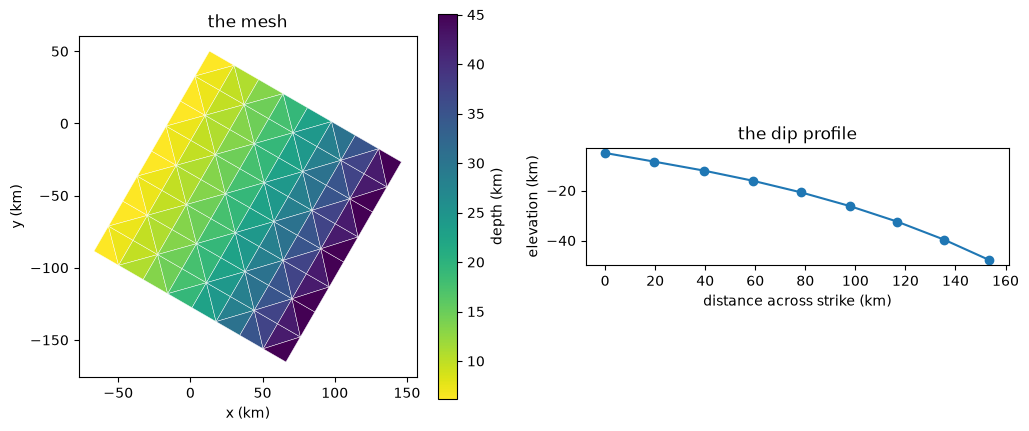

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
depth = V[F].mean(1)[:, 2]
pc = ax1.tripcolor(V[:, 0], V[:, 1], F, facecolors=depth, cmap='viridis_r', edgecolors='w', lw=0.3)
fig.colorbar(pc, ax=ax1, label='depth (km)')
ax1.set_aspect('equal'); ax1.set_xlabel('x (km)'); ax1.set_ylabel('y (km)'); ax1.set_title('the mesh')
# the down-dip profile: the vertices of the first column, against their horizontal distance from the top edge
column = np.isclose(uv[:, 0], 0.0)
x0, y0 = fault.ll2xy(-80.6, -0.8)
phi = np.radians(30.0)
horizontal = (V[column, 0] - x0) * np.cos(phi) - (V[column, 1] - y0) * np.sin(phi)
ax2.plot(horizontal, -V[column, 2], 'o-')
ax2.set_aspect('equal'); ax2.set_xlabel('distance across strike (km)'); ax2.set_ylabel('elevation (km)')
ax2.set_title('the dip profile')
plt.show()

## Rakes and source points

The slip of each patch has two components: along the convergence of the Nazca plate, N83°E, and across it. `convergenceRakes` gives the rake of each patch for slip along the convergence: the hanging wall moving against the subducting plate, projected on the patch. The rake across the convergence is 90° more.

A patch tens of kilometers across radiates differently from a point at its centroid. `setSourcePoints(3)` cuts each triangle into 3 × 3 smaller ones and places a point source at the centroid of each; the Green's functions of a patch sum the seismograms of its nine points, each with a ninth of its moment, and AlTar takes the rupture time at each of them, so that a patch slips progressively as the rupture front crosses it.

In [4]:
fault.setSourcePoints(3)
# slip along the convergence of the Nazca plate, N83E, and across it
parallel = fault.convergenceRakes(83.0)
rakes = (parallel + 90.0, parallel)
print(f"rake along the convergence: {parallel.min():.1f} to {parallel.max():.1f} degrees")
print(f"source points: {fault.sources_per_patch} a patch, {len(fault.sources_xyz)} in all")

rake along the convergence: 127.4 to 129.6 degrees
source points: 9 a patch, 1152 in all


## Stations

The stations are on land, east of a coast 45 km from the trench, and at least 1 km from every source point: 18 high-rate GPS or strong motion stations for the waveforms, 30 GPS stations for the static offsets, and the points of an InSAR-like grid. Each set is a `csi.seismic` object.

In [5]:
rng = np.random.default_rng(2016)
coast = 45.0
sources = fault.sources_xyz[:, :2]
# a point at {a} km along strike and {c} km east of the trench, across it
point = lambda a, c: (x0 + a * np.sin(phi) + c * np.cos(phi), y0 + a * np.cos(phi) - c * np.sin(phi))

def land(count, near, far, spread=20.0):
    # {count} places on land, {near} to {far} km east of the coast, at least 1 km from every source
    places = []
    while len(places) < count:
        a, c = rng.uniform(-spread, 160.0 + spread), coast + rng.uniform(near, far)
        x, y = point(a, c)
        if np.hypot(sources[:, 0] - x, sources[:, 1] - y).min() >= 1.0:
            places.append((x, y))
    return np.array(places)

def stations(name, places, prefix):
    names = [f"{prefix}{k:03d}" for k in range(len(places))]
    data = csi.seismic(name, lon0=-80.0, lat0=0.0)
    data.setStat(names, *fault.xy2ll(places[:, 0], places[:, 1]), loc_format="LL")
    return data

kinematic = stations("kinematic", land(18, 2.0, 120.0), "K")
gps = stations("gps", land(30, 2.0, 150.0), "G")
ga, gc = np.meshgrid(np.linspace(-10, 170, 12), coast + np.linspace(3, 100, 10), indexing="ij")
insar_xy = np.array([point(a, c) for a, c in zip(ga.ravel(), gc.ravel())])
insar_xy = insar_xy[[np.hypot(sources[:, 0] - x, sources[:, 1] - y).min() >= 1.0 for x, y in insar_xy]]
insar = stations("insar", insar_xy, "I")
print(f"{len(kinematic.sta_name)} waveform stations, {len(gps.sta_name)} gps, {len(insar.sta_name)} line of sight points")

18 waveform stations, 30 gps, 98 line of sight points


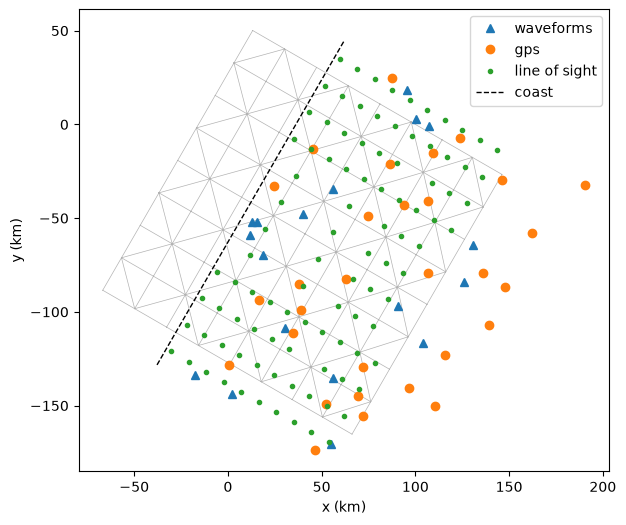

In [6]:
fig, ax = plt.subplots(figsize=(7, 6))
ax.triplot(V[:, 0], V[:, 1], F, color='0.7', lw=0.5)
for data, marker, label in [(kinematic, '^', 'waveforms'), (gps, 'o', 'gps'), (insar, '.', 'line of sight')]:
    x, y = fault.ll2xy(np.asarray(data.lon), np.asarray(data.lat))
    ax.plot(x, y, marker, label=label)
ax.plot(*point(np.array([-20, 180]), coast), 'k--', lw=1, label='coast')
ax.set_aspect('equal'); ax.set_xlabel('x (km)'); ax.set_ylabel('y (km)'); ax.legend()
plt.show()

## The kinematic Green's functions

`buildKinGFs` computes the seismograms of each patch for a unit slip along each rake, released by a triangle of 2 s centered at time 0, on a time axis that starts 40 s early: some stores have small precursors before the arrivals, which the engine reports if they fall before the axis. The seismograms are bandpassed between 0.015 and 0.08 Hz, as the data would be.

`buildBigGD` then makes the big G of AlTar's kinematic model: one column per time step of 1 s, rake and patch, the seismograms delayed by the time step, so that the data are big G times the slip history, the slip each patch releases in each time step.

In [7]:
engine = csi.pyrockoengine("crust2_2hz_d0", store_dir, delta=1.0)
fault.setMu(engine.material)
start = time.perf_counter()
fault.buildKinGFs(kinematic, engine, Dt=1.0, npts=160, rakes=rakes, points=True,
                  bandpass=(0.015, 0.08))
fault.buildBigGD(kinematic, Nt=85, Dt=1.0)
print(f"{time.perf_counter() - start:.0f} s; precursors cut off: {engine.lost:.1e} of a station's peak at most")
print(f"big G: {fault.bigG.shape[0]} data samples x {fault.bigG.shape[1]} slip windows (85 steps x 2 rakes x {Np} patches)")
print(f"shear modulus: {fault.mu.min() / 1e9:.0f} to {fault.mu.max() / 1e9:.0f} GPa")

15 s; precursors cut off: 4.8e-05 of a station's peak at most
big G: 8640 data samples x 21760 slip windows (85 steps x 2 rakes x 128 patches)
shear modulus: 36 to 72 GPa


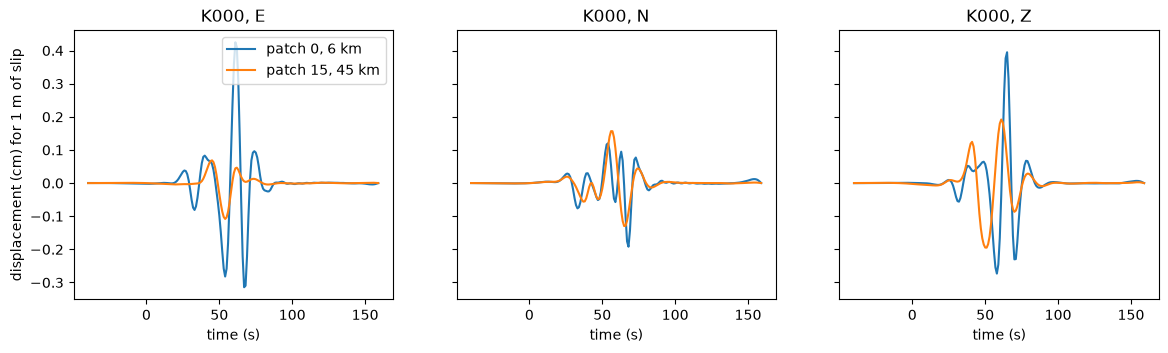

In [8]:
# the seismograms of a patch near the trench and of a deep one, at the first station, for slip along the convergence
G = fault.G[kinematic.name][1]
t = (np.arange(G.shape[-1]) - fault.kin_pre) * fault.kin_delta
shallow, deep = np.argmin(depth), np.argmax(depth)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5), sharey=True)
for c, ax in enumerate(axes):
    for p, label in [(shallow, f'patch {shallow}, {depth[shallow]:.0f} km'), (deep, f'patch {deep}, {depth[deep]:.0f} km')]:
        ax.plot(t, 100 * G[p, 0, c], label=label)
    ax.set_title(f"{kinematic.sta_name[0]}, {'ENZ'[c]}"); ax.set_xlabel('time (s)')
axes[0].set_ylabel('displacement (cm) for 1 m of slip'); axes[0].legend()
plt.show()

## The static Green's functions

`buildStaticGFs` takes the final values of the seismograms of the same engine, unfiltered and long enough for the waves to pass, so that the static data share the earth model of the waveforms. The InSAR Green's functions are projected on the line of sight of a descending track.

With `method='cuokada'` (or `'cutde'`), they are those of triangular dislocations in a homogeneous half space instead. The two differ, a layered earth against a homogeneous one, but their patterns must agree: a comparison catches a mix-up of signs or rakes.

In [9]:
start = time.perf_counter()
Ggps = fault.buildStaticGFs(gps, engine, rakes=rakes, points=True)
Gins = fault.buildStaticGFs(insar, engine, rakes=rakes, points=True)
los = np.array([0.62, -0.11, 0.78])  # east, north, up: a descending track
Glos = np.einsum("c,scp->sp", los, Gins.reshape(len(insar.sta_name), 3, -1))
print(f"{time.perf_counter() - start:.0f} s; gps {Ggps.shape}, line of sight {Glos.shape}")

100 s; gps (90, 256), line of sight (98, 256)


engine against half space, column by column: correlation median 0.989, lowest 0.982; amplitude ratio median 1.09


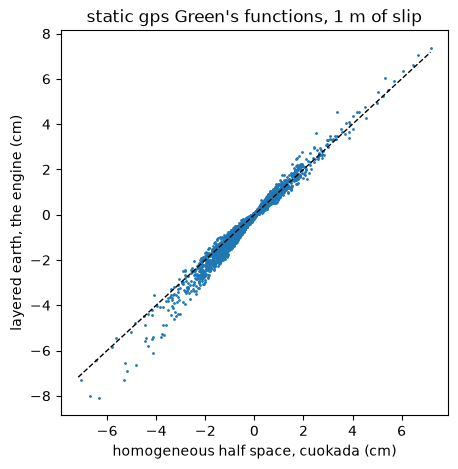

In [10]:
try:
    import cuokada
except ImportError:
    cuokada = None
    print("cuokada is not installed: no comparison with the half space")
if cuokada is not None:
    Ghs = fault.buildStaticGFs(gps, rakes=rakes, method='cuokada')
    corr = [np.corrcoef(Ggps[:, k], Ghs[:, k])[0, 1] for k in range(Ggps.shape[1])]
    ratio = np.linalg.norm(Ggps, axis=0) / np.linalg.norm(Ghs, axis=0)
    print(f"engine against half space, column by column: correlation median {np.median(corr):.3f}, lowest {np.min(corr):.3f}; "
          f"amplitude ratio median {np.median(ratio):.2f}")
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.plot(100 * Ghs.ravel(), 100 * Ggps.ravel(), '.', ms=2)
    lim = 100 * np.abs(Ghs).max()
    ax.plot([-lim, lim], [-lim, lim], 'k--', lw=1)
    ax.set_xlabel('homogeneous half space, cuokada (cm)'); ax.set_ylabel('layered earth, the engine (cm)')
    ax.set_title('static gps Green\'s functions, 1 m of slip')
    plt.show()

## A synthetic rupture

The true model of the Pedernales-like synthetic: a 3 m asperity next to the hypocenter in the north, a 6 m one 70 km south, slip across the convergence of up to 0.3 m, rise times from 4 to 10 s that grow with the slip, and a rupture velocity for each block of 2 × 2 cells, 16 groups, from 2.2 to 3.1 km/s, faster to the north.

With rupture velocities that vary, the rupture front comes from the eikonal equation, so the slip history is that of AlTar's kinematic model on triangular meshes, `altar.models.seismic.kinematicmesh`: the front spreads from the hypocenter by the fast iterative method, on a mesh refined from the patches, and each source point of a patch releases its share of the slip as a triangle of the rise time, starting when the front reaches it; the slip of the patch in each time step is that function sampled at the start of the step. The `forward` action of AlTar computes it for the true parameters, with the kinematic model alone, on the cpu, in double precision (`synthetic.pfg`); it reads its inputs from `input/`, written here: the mesh with the hypocenter and the velocity groups, and the big G (the waveforms aren't known yet; zeros hold their place).

The data are then big G times the slip history for the waveforms, and the static Green's functions times the final slip for the GPS and the line of sight.

In [11]:
import h5py
# the true model, on the centroids of the patches in surface coordinates
uvc = np.array([uv[f].mean(0) for f in F])
a = np.exp(-((uvc - [118.0, 60.0]) ** 2).sum(1) / (2 * 15.0 ** 2))
b = np.exp(-((uvc - [55.0, 75.0]) ** 2).sum(1) / (2 * 18.0 ** 2))
slip_parallel = 0.2 + 3.0 * a + 6.0 * b
slip_across = 0.3 * (a - b)
risetime = 4.0 + 6.0 * (slip_parallel - slip_parallel.min()) / (slip_parallel.max() - slip_parallel.min())
hypocenter = np.array([125.0, 55.0])
# a rupture velocity for each block of 2 x 2 cells, 40 km on a side
blocks = np.clip((uvc / 40.0).astype(int), 0, 3)
groups = blocks[:, 0] * 4 + blocks[:, 1]
centers = np.array([uvc[groups == g].mean(0) for g in range(16)])
velocity = 2.2 + 0.6 * centers[:, 0] / 160.0 + 0.3 * np.sin(centers[:, 1] / 30.0)
print(f"rupture velocities: {velocity.min():.2f} to {velocity.max():.2f} km/s")

# AlTar's inputs: the mesh, the hypocenter and the velocity groups, the big G, and the true parameters
os.makedirs('input', exist_ok=True)
os.chdir('input')
fault.setHypoOnFault(*hypocenter)
fault.bigD = np.zeros(fault.bigG.shape[0])
fault.saveKinematic('mesh.h5')
with h5py.File('mesh.h5', 'a') as h5:
    h5['groups/velocity'] = groups
np.savetxt('truth.txt', np.concatenate([slip_across, slip_parallel, risetime, velocity, hypocenter])[None, :])
os.chdir('..')

rupture velocities: 1.98 to 3.00 km/s


In [12]:
print(open('synthetic.pfg').read())

; step 1: the slip history and the waveforms of the true model, from the kinematic model alone, on
; the cpu in double precision; the priors don't matter here, only the layout of the parameters
slipmodel:
    model = altar.models.seismic.kinematicmesh
    model:
        case = input
        mesh = mesh.h5
        refine = 10
        velocity_groups = groups/velocity
        patches = 128
        green = kinematicG.gf.h5
        dataobs:
            observations = 8640
            data_file = kinematicG.data.h5
            cd_std = 5.0e-3
        Nt = 85
        dt = 1.0
        psets_list = [across, parallel, risetime, rupturevelocity, hypocenter]
        psets:
            across = contiguous
            parallel = contiguous
            risetime = contiguous
            rupturevelocity = contiguous
            hypocenter = contiguous
            across:
                count = {slipmodel.model.patches}
                prior = gaussian
                prior.mean = 0
                pr

In [13]:
!slipmodel.plexus forward --config=synthetic.pfg > input/synthetic.log 2>&1

In [14]:
# the slip history Mb[Nt][2][Np] of the true model, the components in the order of the rakes
Nt, dt = 85, 1.0
tk = np.arange(Nt) * dt
with h5py.File('input/truth.forward.h5') as h5:
    Mb = np.asarray(h5['Mb/mean_model']).reshape(Nt, 2, Np)
# the mean onset of the source points of each patch: the centroid time of its slip, less half its rise time
patch_onset = (tk[:, None] * Mb[:, 1]).sum(0) / Mb[:, 1].sum(0) - risetime / 2
moment = (fault.mu * np.asarray(fault.area) * 1e6 * np.hypot(slip_across, slip_parallel)).sum()
end = np.flatnonzero(np.abs(Mb).sum((1, 2)) > 0).max() + 1
print(f"Mw {2 / 3 * (np.log10(moment) - 9.1):.2f}; the rupture lasts {end * dt:.0f} s of the {Nt} s of slip windows")

# the data
waveforms = fault.bigG @ Mb.ravel()
final = np.concatenate([slip_across, slip_parallel])
offsets, line_of_sight = Ggps @ final, Glos @ final
print(f"waveforms: {waveforms.size} samples, peak {100 * np.abs(waveforms).max():.1f} cm; "
      f"gps: peak {100 * np.abs(offsets).max():.1f} cm; line of sight: {100 * line_of_sight.min():.1f} to {100 * line_of_sight.max():.1f} cm")

Mw 7.90; the rupture lasts 73 s of the 85 s of slip windows
waveforms: 8640 samples, peak 34.0 cm; gps: peak 116.5 cm; line of sight: -89.9 to 7.3 cm


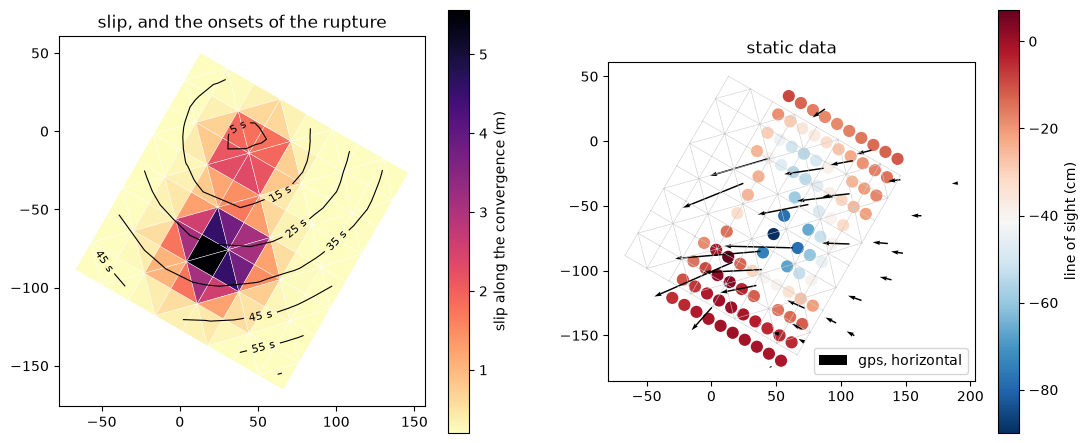

In [15]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.5))
pc = ax1.tripcolor(V[:, 0], V[:, 1], F, facecolors=slip_parallel, cmap='magma_r', edgecolors='w', lw=0.3)
fig.colorbar(pc, ax=ax1, label='slip along the convergence (m)')
centroids = V[F].mean(1)
cs = ax1.tricontour(centroids[:, 0], centroids[:, 1], patch_onset, levels=np.arange(5, 75, 10), colors='k', linewidths=0.8)
ax1.clabel(cs, fmt='%d s', fontsize=8)
ax1.set_aspect('equal'); ax1.set_title('slip, and the onsets of the rupture')
# the gps offsets and the line of sight
gx, gy = fault.ll2xy(np.asarray(gps.lon), np.asarray(gps.lat))
ix, iy = fault.ll2xy(np.asarray(insar.lon), np.asarray(insar.lat))
sc = ax2.scatter(ix, iy, c=100 * line_of_sight, cmap='RdBu_r', s=60)
fig.colorbar(sc, ax=ax2, label='line of sight (cm)')
o = offsets.reshape(-1, 3)
ax2.quiver(gx, gy, o[:, 0], o[:, 1], scale=5, width=0.004, label='gps, horizontal')
ax2.triplot(V[:, 0], V[:, 1], F, color='0.8', lw=0.4)
ax2.set_aspect('equal'); ax2.set_title('static data'); ax2.legend(loc='lower right')
plt.show()

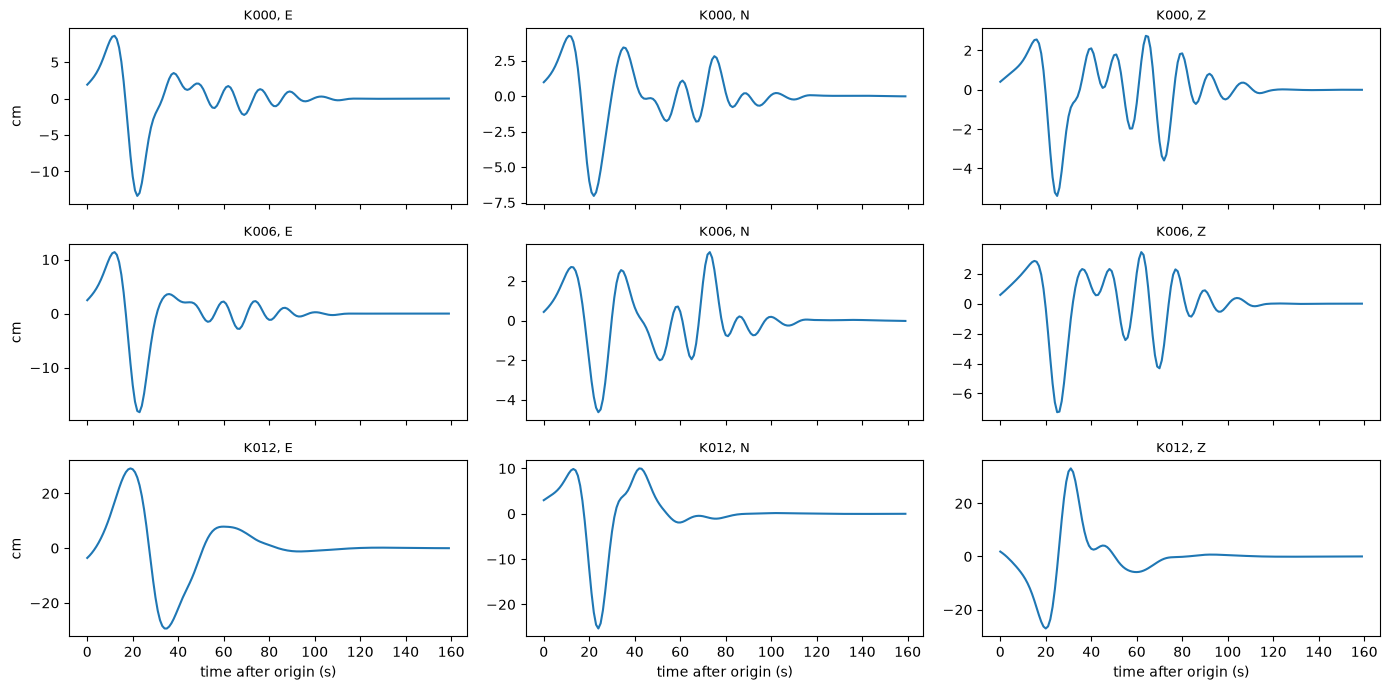

In [16]:
# the waveforms at three stations
traces = waveforms.reshape(len(kinematic.sta_name), 3, -1)
t = np.arange(traces.shape[-1]) * fault.kin_delta
fig, axes = plt.subplots(3, 3, figsize=(14, 7), sharex=True)
for row, s in enumerate([0, 6, 12]):
    for c in range(3):
        axes[row, c].plot(t, 100 * traces[s, c])
        axes[row, c].set_title(f"{kinematic.sta_name[s]}, {'ENZ'[c]}", fontsize=9)
    axes[row, 0].set_ylabel('cm')
for ax in axes[-1]:
    ax.set_xlabel('time after origin (s)')
fig.tight_layout()
plt.show()

## The inverse problem: a linear least squares solution

The data are linear in the slip history: the waveforms are big G times the slip of each patch along each rake in each time step, and the static data are the static Green's functions times the final slip, the sum over the time steps. With the hypocenter known (here the true one; for an earthquake, that of a catalog), this is the classic linear multiple-time-window inversion (e.g. Olson and Apsel, 1982; Hartzell and Heaton, 1983), solved here by regularized least squares:

- **the unknowns** are the slips of each patch in the time steps the rupture can reach it in: after the front at 3.5 km/s, and before the front at 1.5 km/s plus the longest rise time, as `RectangularPatchesKin` does with its `vmax`;
- **the data** get noise first, 0.5 cm on the waveforms and the GPS and 1 cm on the line of sight, and are weighted by it;
- **the regularization** smooths the slip in space, with the Laplacian of the mesh in each time step, and in time, with the differences between consecutive time steps of each patch, plus a little damping; its weight is set so that the fit matches the noise, a chi-square per datum of about 1 (the discrepancy principle).

Positivity of the slip along the convergence, or the posterior uncertainties, take a bounded least squares (`scipy.optimize.lsq_linear`) or a Bayesian sampler such as AlTar instead.

In [17]:
# the synthetic data, with noise
noise = rng  # the generator of the stations, on
sigma = {'waveforms': 0.005, 'gps': 0.005, 'line of sight': 0.01}
d_waveforms = waveforms + sigma['waveforms'] * noise.standard_normal(waveforms.size)
d_gps = offsets + sigma['gps'] * noise.standard_normal(offsets.size)
d_los = line_of_sight + sigma['line of sight'] * noise.standard_normal(line_of_sight.size)

# the unknowns: the time steps each patch can slip in, between the fronts at vmax and vmin
vmax, vmin = 3.5, 1.5
distance = np.linalg.norm(fault.sources_uv - hypocenter, axis=1)
near = np.full(Np, np.inf); far = np.zeros(Np)
np.minimum.at(near, fault.sources_patch, distance); np.maximum.at(far, fault.sources_patch, distance)
first = np.floor(near / vmax / dt).astype(int)
last = np.minimum(np.ceil((far / vmin + 10.0) / dt).astype(int), Nt - 1)
k = np.arange(Nt)[:, None, None]
active = ((k >= first) & (k <= last)) & np.ones((1, 2, 1), bool)
columns = np.flatnonzero(active.ravel())
n = columns.size
print(f"{n} unknowns, of the {active.size} slip windows of big G")

11470 unknowns, of the 21760 slip windows of big G


In [18]:
import scipy.sparse as sp
import scipy.linalg

# the data equations, weighted by the noise: the waveforms, and the static data through the final slip
final = sp.csr_matrix((np.full(n, dt), ((columns // Np) % 2 * Np + columns % Np, np.arange(n))), shape=(2 * Np, n))
A = np.vstack([fault.bigG[:, columns] / sigma['waveforms'],
               (final.T @ (Ggps / sigma['gps']).T).T,
               (final.T @ (Glos / sigma['line of sight']).T).T])
b = np.concatenate([d_waveforms / sigma['waveforms'], d_gps / sigma['gps'], d_los / sigma['line of sight']])
counts = {'waveforms': d_waveforms.size, 'gps': d_gps.size, 'line of sight': d_los.size}

# the regularization, on the whole grid of slip windows and restricted to the unknowns: the laplacian of the
# mesh in each time step and rake, scaled to one on its diagonal, and the differences between time steps
laplacian = fault.buildLaplacian(verbose=False)
laplacian = sp.csr_matrix(laplacian / np.abs(np.diag(laplacian)).mean())
space = sp.kron(sp.identity(2 * Nt), laplacian, format='csr')[:, columns]
step = sp.diags([-np.ones(Nt - 1), np.ones(Nt - 1)], [0, 1], shape=(Nt - 1, Nt))
time_ = sp.kron(step, sp.identity(2 * Np), format='csr')[:, columns]
R = (space.T @ space + (time_.T @ time_)).toarray()
AtA, Atb = A.T @ A, A.T @ b
print(f"the data equations: {A.shape[0]} data x {n} unknowns")

def solve(weight):
    # the regularized least squares solution, and its chi-square per datum on each data set
    x = scipy.linalg.solve(AtA + weight ** 2 * R + (0.01 * weight) ** 2 * np.identity(n), Atb, assume_a='pos')
    r = A @ x - b
    edges = np.cumsum([0] + list(counts.values()))
    return x, {name: (r[edges[i]:edges[i + 1]] ** 2).mean() for i, name in enumerate(counts)}, (r ** 2).mean()

scan = {}
for weight in [1, 3, 10, 30, 100, 300]:
    x, chi2, total = solve(weight)
    scan[weight] = total
    print(f"weight {weight:5g}: chi-square per datum {total:.2f} (" + ", ".join(f"{k} {v:.2f}" for k, v in chi2.items()) + ")")

the data equations: 8828 data x 11470 unknowns


weight     1: chi-square per datum 0.77 (waveforms 0.78, gps 0.25, line of sight 0.39)


weight     3: chi-square per datum 0.83 (waveforms 0.84, gps 0.32, line of sight 0.46)


weight    10: chi-square per datum 0.88 (waveforms 0.89, gps 0.38, line of sight 0.57)


weight    30: chi-square per datum 0.94 (waveforms 0.95, gps 0.52, line of sight 0.72)


weight   100: chi-square per datum 1.33 (waveforms 1.33, gps 1.49, line of sight 1.39)


weight   300: chi-square per datum 4.53 (waveforms 4.44, gps 13.07, line of sight 4.69)


In [19]:
# the weight whose fit matches the noise best
weight = min(scan, key=lambda w: abs(scan[w] - 1))
x, chi2, total = solve(weight)
inverted = np.zeros(active.size); inverted[columns] = x
Mb_inv = inverted.reshape(Nt, 2, Np)
slip_inv = Mb_inv.sum(0) * dt
true_final = Mb.sum(0) * dt
moment_inv = (fault.mu * np.asarray(fault.area) * 1e6 * np.hypot(*slip_inv)).sum()
corr = np.corrcoef(slip_inv[1], true_final[1])[0, 1]
print(f"weight {weight}: chi-square per datum {total:.2f}")
print(f"slip along the convergence: correlation with the truth {corr:.3f}, largest {slip_inv[1].max():.2f} m against {true_final[1].max():.2f} m")
print(f"Mw {2 / 3 * (np.log10(moment_inv) - 9.1):.2f} against {2 / 3 * (np.log10(moment) - 9.1):.2f}")
for name, d, prediction in [('waveforms', d_waveforms, fault.bigG @ inverted),
                            ('gps', d_gps, Ggps @ slip_inv.ravel()), ('line of sight', d_los, Glos @ slip_inv.ravel())]:
    print(f"{name}: variance reduction {1 - ((d - prediction) ** 2).sum() / (d ** 2).sum():.3f}")

weight 30: chi-square per datum 0.94
slip along the convergence: correlation with the truth 0.990, largest 5.33 m against 5.57 m
Mw 7.91 against 7.90
waveforms: variance reduction 0.991
gps: variance reduction 1.000
line of sight: variance reduction 0.999


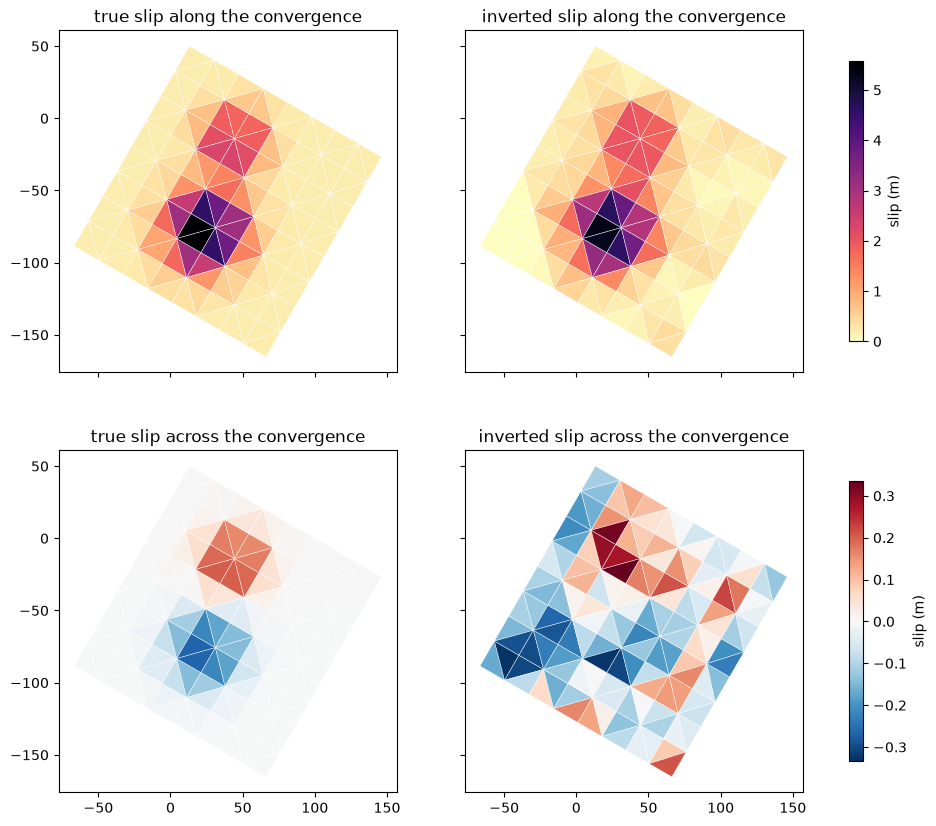

In [20]:
# the final slip: true and inverted
fig, axes = plt.subplots(2, 2, figsize=(12, 10), sharex=True, sharey=True)
for row, (component, label, cmap) in enumerate([(1, 'along the convergence', 'magma_r'), (0, 'across the convergence', 'RdBu_r')]):
    values = [true_final[component], slip_inv[component]]
    if component == 1:
        lo, hi = 0, max(v.max() for v in values)
    else:
        hi = max(np.abs(v).max() for v in values); lo = -hi
    for col, (v, title) in enumerate(zip(values, ['true', 'inverted'])):
        ax = axes[row, col]
        pc = ax.tripcolor(V[:, 0], V[:, 1], F, facecolors=v, cmap=cmap, vmin=lo, vmax=hi, edgecolors='w', lw=0.3)
        ax.set_aspect('equal'); ax.set_title(f'{title} slip {label}')
    fig.colorbar(pc, ax=axes[row], label='slip (m)', shrink=0.8)
plt.show()

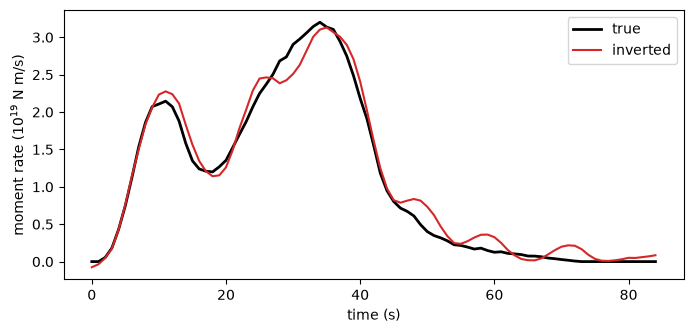

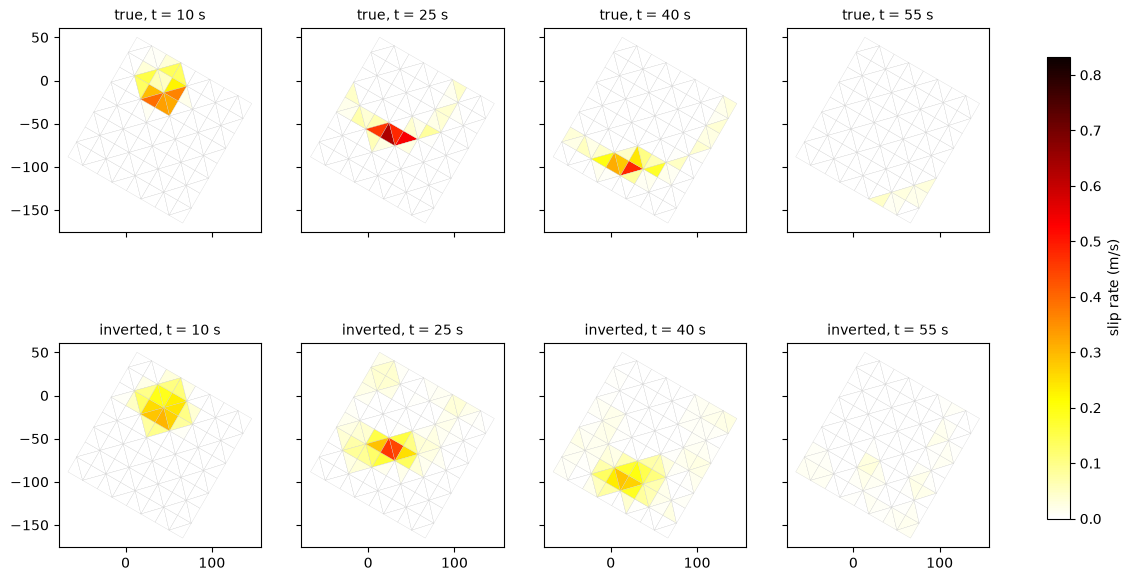

In [21]:
# the slip of each time step along the final slip of its patch: small values of either sign, the noise
# the inversion fits, then cancel, as they would not in the magnitude of the slip
def along_final(history, final_slip):
    direction = final_slip / np.maximum(np.hypot(*final_slip), 1e-12)
    return (history * direction[None]).sum(1)

# the moment rate, and the slip rate at a few times
rate_moment = lambda history, final_slip: (fault.mu * np.asarray(fault.area) * 1e6 * along_final(history, final_slip)).sum(1) / dt
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(tk, rate_moment(Mb, true_final) / 1e19, 'k', lw=2, label='true')
ax.plot(tk, rate_moment(Mb_inv, slip_inv) / 1e19, 'C3', label='inverted')
ax.set_xlabel('time (s)'); ax.set_ylabel('moment rate (10$^{19}$ N m/s)'); ax.legend()
plt.show()

times = [10, 25, 40, 55]
fig, axes = plt.subplots(2, len(times), figsize=(15, 7.5), sharex=True, sharey=True)
rates = {'true': along_final(Mb, true_final) / dt, 'inverted': along_final(Mb_inv, slip_inv) / dt}
peak = rates['true'].max()
for col, tt in enumerate(times):
    for row, title in enumerate(['true', 'inverted']):
        ax = axes[row, col]
        pc = ax.tripcolor(V[:, 0], V[:, 1], F, facecolors=np.clip(rates[title][tt], 0, None), cmap='hot_r', vmin=0, vmax=peak,
                          edgecolors='0.8', lw=0.2)
        ax.set_aspect('equal'); ax.set_title(f'{title}, t = {tt} s', fontsize=10)
fig.colorbar(pc, ax=axes, label='slip rate (m/s)', shrink=0.8)
plt.show()

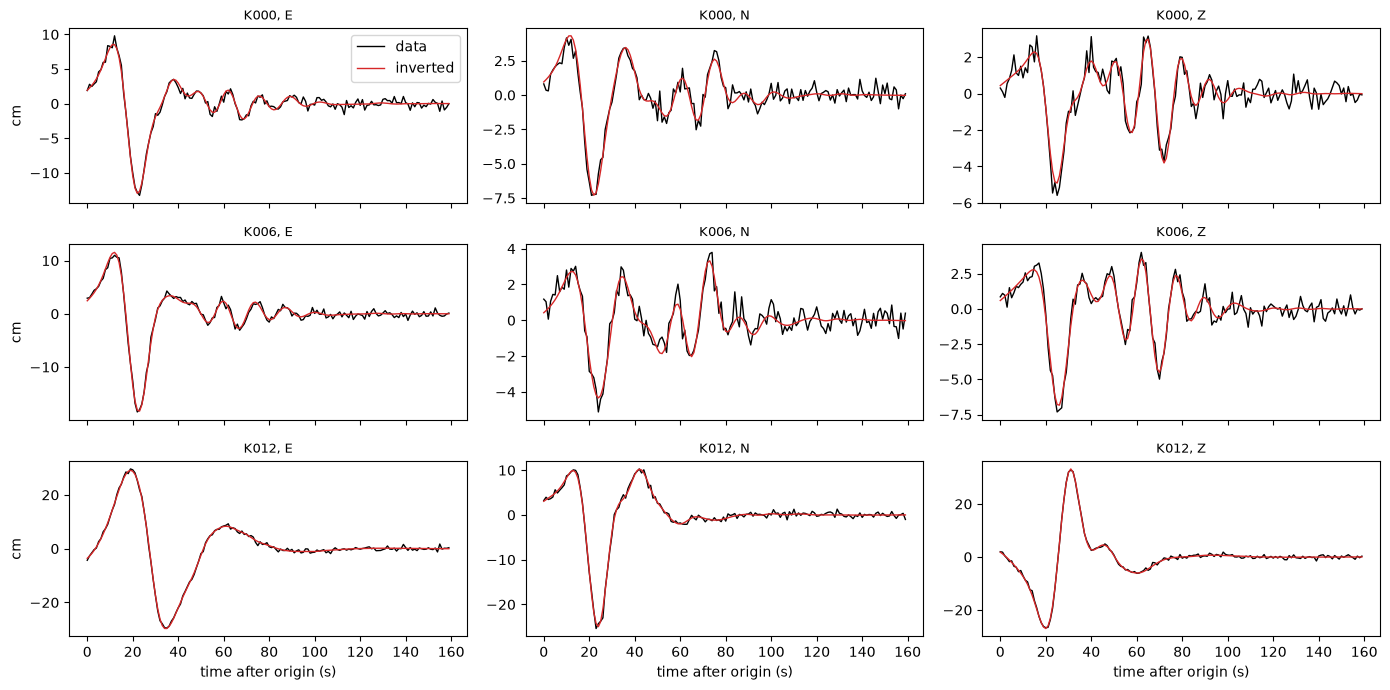

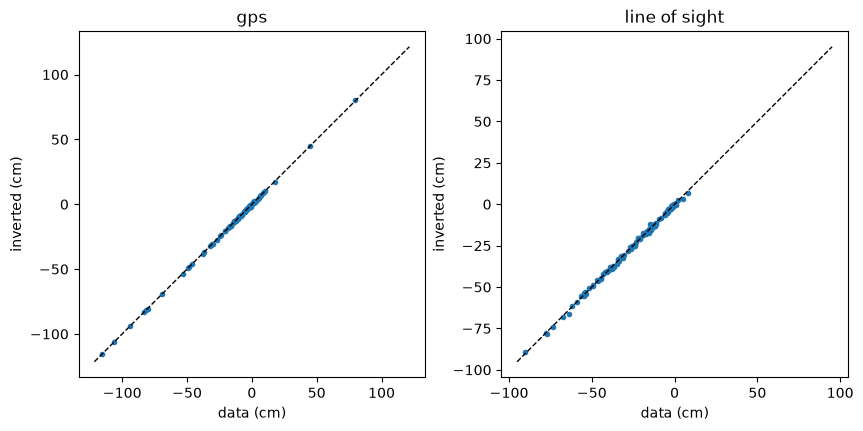

In [22]:
# the fits: the waveforms at three stations, and the static data
predicted = (fault.bigG @ inverted).reshape(len(kinematic.sta_name), 3, -1)
observed = d_waveforms.reshape(len(kinematic.sta_name), 3, -1)
t = np.arange(observed.shape[-1]) * fault.kin_delta
fig, axes = plt.subplots(3, 3, figsize=(14, 7), sharex=True)
for row, s in enumerate([0, 6, 12]):
    for c in range(3):
        axes[row, c].plot(t, 100 * observed[s, c], 'k', lw=1, label='data')
        axes[row, c].plot(t, 100 * predicted[s, c], 'C3', lw=1, label='inverted')
        axes[row, c].set_title(f"{kinematic.sta_name[s]}, {'ENZ'[c]}", fontsize=9)
    axes[row, 0].set_ylabel('cm')
axes[0, 0].legend()
for ax in axes[-1]:
    ax.set_xlabel('time after origin (s)')
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, (name, d, prediction) in zip(axes, [('gps', d_gps, Ggps @ slip_inv.ravel()), ('line of sight', d_los, Glos @ slip_inv.ravel())]):
    ax.plot(100 * d, 100 * prediction, '.')
    lim = 100 * np.abs(d).max() * 1.05
    ax.plot([-lim, lim], [-lim, lim], 'k--', lw=1)
    ax.set_xlabel('data (cm)'); ax.set_ylabel('inverted (cm)'); ax.set_title(name); ax.set_aspect('equal')
plt.show()

## The files for AlTar

AlTar's inputs, in `input/`:

- for the kinematic model on triangular meshes, `altar.models.seismic.kinematicmesh`, what `saveKinematic` wrote for the synthetic: the mesh, its surface coordinates, the source points, the hypocenter and the velocity groups (`mesh.h5`) and the big G (`kinematicG.gf.h5`); and now the noisy waveforms (`kinematicG.data.h5`);
- for the static model, `altar.models.seismic.static`: the Green's functions of the GPS and the line of sight, one column per rake and patch (`static.gf.h5`), their noisy data (`static.data.h5`) and its covariance (`static.Cd.h5`);
- for the comparison in step 2, `synthetic.h5`: the true model in AlTar's parameters, the true slip history, the least squares solution, and what the figures need.

In [23]:
os.chdir('input')
# the kinematic model: the mesh and the big G are in already, the waveforms take the place of the zeros
with h5py.File('kinematicG.data.h5', 'w') as h5:
    h5['kinematicG.data'] = d_waveforms
# the static model: the gps then the line of sight; the columns across then along the convergence, as the rakes
d_static = np.concatenate([d_gps, d_los])
sigma_static = np.concatenate([np.full(d_gps.size, sigma['gps']), np.full(d_los.size, sigma['line of sight'])])
for name, values in [('static.gf', np.vstack([Ggps, Glos])), ('static.data', d_static),
                     ('static.Cd', np.diag(sigma_static ** 2))]:
    with h5py.File(f'{name}.h5', 'w') as h5:
        h5[name] = values
# the truth, in AlTar's parameters, the least squares solution, and what the figures of step 2 need
with h5py.File('synthetic.h5', 'w') as h5:
    for name, values in [('across', slip_across), ('parallel', slip_parallel), ('risetime', risetime),
                         ('rupturevelocity', velocity), ('hypocenter', hypocenter)]:
        h5[f'true/{name}'] = values
    h5['true/Mb'] = Mb
    h5['leastsquares/Mb'] = Mb_inv
    h5['leastsquares/weight'] = weight
    h5['mu'], h5['area'], h5['dt'] = fault.mu, np.asarray(fault.area), dt
    h5['stations'] = np.array(kinematic.sta_name, dtype='S')
    h5['gps/xy'] = np.column_stack(fault.ll2xy(np.asarray(gps.lon), np.asarray(gps.lat)))
    h5['los/xy'] = np.column_stack(fault.ll2xy(np.asarray(insar.lon), np.asarray(insar.lat)))
for name in sorted(n for n in os.listdir('.') if n.endswith('.h5')):
    shapes = []
    with h5py.File(name) as h5:
        h5.visititems(lambda key, item: shapes.append(f"{key} {item.shape}") if isinstance(item, h5py.Dataset) else None)
    print(f"{name}, {os.path.getsize(name) / 1e6:.3g} MB: " + ', '.join(shapes))
os.chdir('..')

kinematicG.data.h5, 0.0712 MB: kinematicG.data (8640,)
kinematicG.gf.h5, 1.5e+03 MB: kinematicG.gf (21760, 8640)
mesh.h5, 0.0442 MB: area (128,), faces (128, 3), groups/velocity (128,), hypocenter (2,), sources/patch (1152,), sources/uv (1152, 2), uv (81, 2), vertices (81, 3)
static.Cd.h5, 0.285 MB: static.Cd (188, 188)
static.data.h5, 0.00355 MB: static.data (188,)
static.gf.h5, 0.387 MB: static.gf (188, 256)
synthetic.h5, 0.367 MB: area (128,), dt (), gps/xy (30, 2), leastsquares/Mb (85, 2, 128), leastsquares/weight (), los/xy (98, 2), mu (128,), stations (18,), true/Mb (85, 2, 128), true/across (128,), true/hypocenter (2,), true/parallel (128,), true/risetime (128,), true/rupturevelocity (16,)
truth.forward.h5, 1.1 MB: Mb/mean (21760,), Mb/mean_model (21760,), Mb/std (21760,), data/mean (8640,), data/mean_model (8640,), data/observed (8640,), data/residual (8640,), data/sigma (8640,), data/sigma_chi (8640,), data/std (8640,), data/whitened_residual (8640,), fit/best_sample/chi2 (), 